In [1]:

import os
import json
import time
import joblib
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.kernel_approximation import Nystroem

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report
)

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid")

RANDOM_STATE = 42

print("Libraries imported successfully!")


Libraries imported successfully!


In [2]:

INPUT_DIR = Path("/kaggle/input")

metadata_files = [
    p for p in INPUT_DIR.rglob("metadata.json")
    if (p.parent / "X_train_scaled.npy").exists()
]

if not metadata_files:
    raise FileNotFoundError(
        "Processed dataset not found. "
        "Please add Notebook 00 output as input."
    )

DATA_DIR = metadata_files[0].parent

print("Dataset directory:", DATA_DIR)

print("\nAvailable files:")
for file in sorted(DATA_DIR.iterdir()):
    print(file.name)


Dataset directory: /kaggle/input/notebooks/ahmadlmomani/00-dry-bean-eda-preprocessing/dry_bean_processed

Available files:
X_test_scaled.csv
X_test_scaled.npy
X_train_scaled.csv
X_train_scaled.npy
imputer.pkl
label_encoder.pkl
metadata.json
scaler.pkl
y_test.csv
y_test.npy
y_train.csv
y_train.npy


In [3]:

X_train = np.load(DATA_DIR / "X_train_scaled.npy")
X_test = np.load(DATA_DIR / "X_test_scaled.npy")

y_train = np.load(DATA_DIR / "y_train.npy")
y_test = np.load(DATA_DIR / "y_test.npy")

with open(DATA_DIR / "metadata.json", "r") as f:
    metadata = json.load(f)

class_names = metadata["classes"]
classes = np.unique(y_train)

print("Dataset loaded successfully!")

print("Training Features:", X_train.shape)
print("Testing Features:", X_test.shape)

print("Training Labels:", y_train.shape)
print("Testing Labels:", y_test.shape)

print("Classes:", class_names)
print("Number of Classes:", len(classes))


Dataset loaded successfully!
Training Features: (10834, 16)
Testing Features: (2709, 16)
Training Labels: (10834,)
Testing Labels: (2709,)
Classes: ['BARBUNYA', 'BOMBAY', 'CALI', 'DERMASON', 'HOROZ', 'SEKER', 'SIRA']
Number of Classes: 7


In [4]:

KERNELS = {
    "Linear": {
        "kernel": "linear"
    },
    "Polynomial": {
        "kernel": "poly",
        "degree": 3,
        "coef0": 0
    },
    "RBF": {
        "kernel": "rbf"
    },
    "Sigmoid": {
        "kernel": "sigmoid",
        "coef0": 0
    }
}

SGD_CONFIG = {
    "learning_rate": 0.001,
    "epochs": 100,
    "regularization": 0.001,
    "n_components": 300
}

print("SGD Configuration:")
print(SGD_CONFIG)

print("\nKernels:")
for name, params in KERNELS.items():
    print(name, params)


SGD Configuration:
{'learning_rate': 0.001, 'epochs': 100, 'regularization': 0.001, 'n_components': 300}

Kernels:
Linear {'kernel': 'linear'}
Polynomial {'kernel': 'poly', 'degree': 3, 'coef0': 0}
RBF {'kernel': 'rbf'}
Sigmoid {'kernel': 'sigmoid', 'coef0': 0}


In [5]:

def train_svm_sgd(
    X,
    y,
    learning_rate=0.001,
    epochs=100,
    reg_strength=0.001,
    random_state=42
):
    n_samples, n_features = X.shape

    classes = np.unique(y)
    n_classes = len(classes)

    # One-vs-Rest labels
    Y = np.where(
        y[:, None] == classes[None, :],
        1.0,
        -1.0
    )

    # Initialize weights
    W = np.zeros((n_features, n_classes))

    loss_history = []

    rng = np.random.default_rng(random_state)

    for epoch in range(epochs):

        # Shuffle training samples
        indices = rng.permutation(n_samples)

        for idx in indices:

            x_i = X[idx]
            y_i = Y[idx]

            # Calculate decision scores
            scores = x_i @ W

            # Calculate hinge margins
            margins = 1 - y_i * scores

            # Identify active hinge losses
            active = (margins > 0).astype(float)

            # Calculate stochastic gradient
            gradient = (
                -np.outer(x_i, y_i * active)
                + reg_strength * W
            )

            # Update weights after ONE sample
            W -= learning_rate * gradient

        # Calculate full training objective after each epoch
        scores = X @ W

        margins = 1 - Y * scores

        hinge_loss = np.maximum(0, margins)

        epoch_loss = (
            np.mean(hinge_loss, axis=0).sum()
            + 0.5 * reg_strength * np.sum(W ** 2)
        )

        loss_history.append(epoch_loss)

        if (epoch + 1) % 10 == 0:
            print(
                f"Epoch {epoch + 1}/{epochs} "
                f"| Loss: {epoch_loss:.4f}"
            )

    return W, loss_history, classes


print("Multiclass SVM with SGD implemented successfully!")


Multiclass SVM with SGD implemented successfully!


In [6]:

sgd_models = {}
sgd_results = []

for kernel_name, kernel_params in KERNELS.items():

    print("\n" + "=" * 60)
    print(f"Training SGD with {kernel_name} Kernel")
    print("=" * 60)

    start_time = time.time()

    # Kernel approximation
    feature_map = Nystroem(
        n_components=SGD_CONFIG["n_components"],
        random_state=RANDOM_STATE,
        gamma=1.0 / X_train.shape[1],
        **kernel_params
    )

    Z_train = feature_map.fit_transform(X_train)
    Z_test = feature_map.transform(X_test)

    # Train using SGD
    W, loss_history, trained_classes = train_svm_sgd(
        Z_train,
        y_train,
        learning_rate=SGD_CONFIG["learning_rate"],
        epochs=SGD_CONFIG["epochs"],
        reg_strength=SGD_CONFIG["regularization"],
        random_state=RANDOM_STATE
    )

    # Predictions
    test_scores = Z_test @ W

    y_pred = trained_classes[
        np.argmax(test_scores, axis=1)
    ]

    training_time = time.time() - start_time

    # Save model components
    sgd_models[kernel_name] = {
        "feature_map": feature_map,
        "weights": W,
        "classes": trained_classes,
        "loss_history": loss_history
    }

    # Evaluate
    sgd_results.append({
        "Kernel": kernel_name,
        "Accuracy": accuracy_score(y_test, y_pred),
        "Precision": precision_score(
            y_test, y_pred,
            average="macro",
            zero_division=0
        ),
        "Recall": recall_score(
            y_test, y_pred,
            average="macro",
            zero_division=0
        ),
        "Macro F1": f1_score(
            y_test, y_pred,
            average="macro",
            zero_division=0
        ),
        "Weighted F1": f1_score(
            y_test, y_pred,
            average="weighted",
            zero_division=0
        ),
        "Final Loss": loss_history[-1],
        "Training Time": training_time
    })

    print(f"\n{kernel_name} completed!")
    print(f"Final Loss: {loss_history[-1]:.4f}")
    print(f"Training Time: {training_time:.2f} seconds")

print("\nAll SGD experiments completed!")



Training SGD with Linear Kernel
Epoch 10/100 | Loss: 3.6994
Epoch 20/100 | Loss: 3.6206
Epoch 30/100 | Loss: 3.5709
Epoch 40/100 | Loss: 3.5455
Epoch 50/100 | Loss: 3.5186
Epoch 60/100 | Loss: 3.5008
Epoch 70/100 | Loss: 3.4890
Epoch 80/100 | Loss: 3.4890
Epoch 90/100 | Loss: 3.4774
Epoch 100/100 | Loss: 3.4645

Linear completed!
Final Loss: 3.4645
Training Time: 40.09 seconds

Training SGD with Polynomial Kernel
Epoch 10/100 | Loss: 4.0731
Epoch 20/100 | Loss: 3.7913
Epoch 30/100 | Loss: 3.6678
Epoch 40/100 | Loss: 3.5979
Epoch 50/100 | Loss: 3.5547
Epoch 60/100 | Loss: 3.5265
Epoch 70/100 | Loss: 3.5072
Epoch 80/100 | Loss: 3.4930
Epoch 90/100 | Loss: 3.4832
Epoch 100/100 | Loss: 3.4757

Polynomial completed!
Final Loss: 3.4757
Training Time: 40.32 seconds

Training SGD with RBF Kernel
Epoch 10/100 | Loss: 0.7787
Epoch 20/100 | Loss: 0.6819
Epoch 30/100 | Loss: 0.6612
Epoch 40/100 | Loss: 0.6530
Epoch 50/100 | Loss: 0.6490
Epoch 60/100 | Loss: 0.6468
Epoch 70/100 | Loss: 0.6454
Epoc

In [7]:

sgd_results_df = pd.DataFrame(sgd_results)

sgd_results_df = sgd_results_df.sort_values(
    by="Macro F1",
    ascending=False
).reset_index(drop=True)

print("Stochastic Gradient Descent Results")

display(
    sgd_results_df.style.format({
        "Accuracy": "{:.4f}",
        "Precision": "{:.4f}",
        "Recall": "{:.4f}",
        "Macro F1": "{:.4f}",
        "Weighted F1": "{:.4f}",
        "Final Loss": "{:.4f}",
        "Training Time": "{:.2f}"
    })
)


Stochastic Gradient Descent Results


,Kernel,Accuracy,Precision,Recall,Macro F1,Weighted F1,Final Loss,Training Time
0,RBF,0.9140,0.9289,0.9236,0.9255,0.9144,0.6434,40.23
1,Sigmoid,0.9040,0.9139,0.9199,0.9163,0.9045,2.4616,40.39
2,Linear,0.8494,0.8329,0.8695,0.8477,0.8495,3.4645,40.09
3,Polynomial,0.8158,0.8687,0.8513,0.8267,0.7850,3.4757,40.32


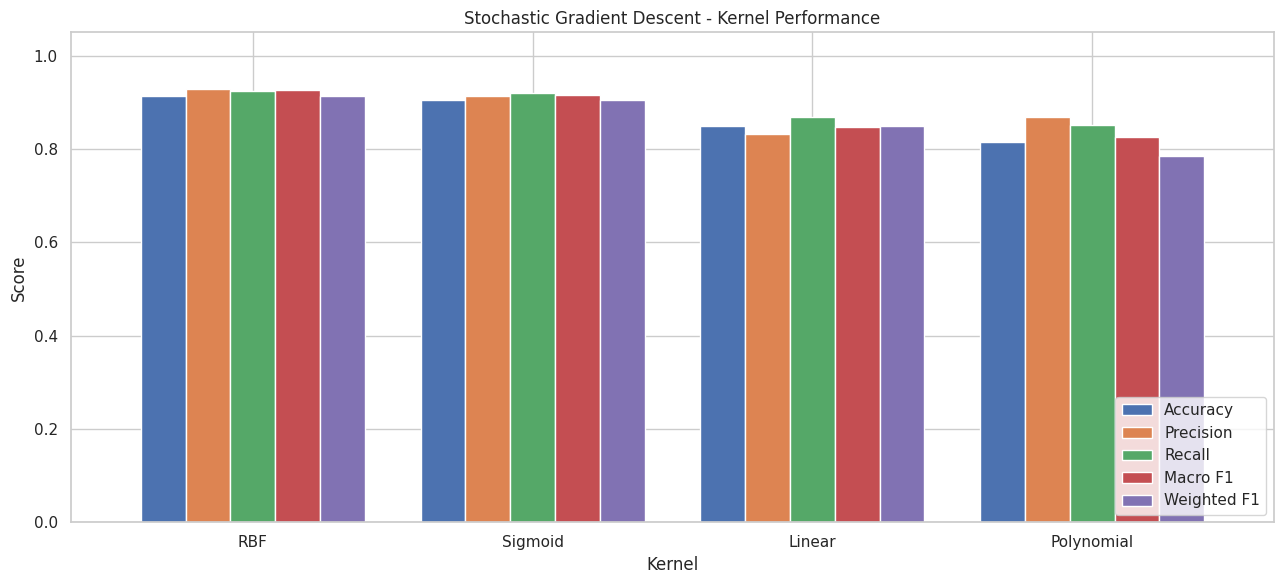

In [8]:

metrics = [
    "Accuracy",
    "Precision",
    "Recall",
    "Macro F1",
    "Weighted F1"
]

sgd_plot = sgd_results_df.set_index("Kernel")[metrics]

sgd_plot.plot(
    kind="bar",
    figsize=(13, 6),
    width=0.8
)

plt.title("Stochastic Gradient Descent - Kernel Performance")
plt.xlabel("Kernel")
plt.ylabel("Score")
plt.ylim(0, 1.05)

plt.xticks(rotation=0)
plt.legend(loc="lower right")

plt.tight_layout()
plt.show()


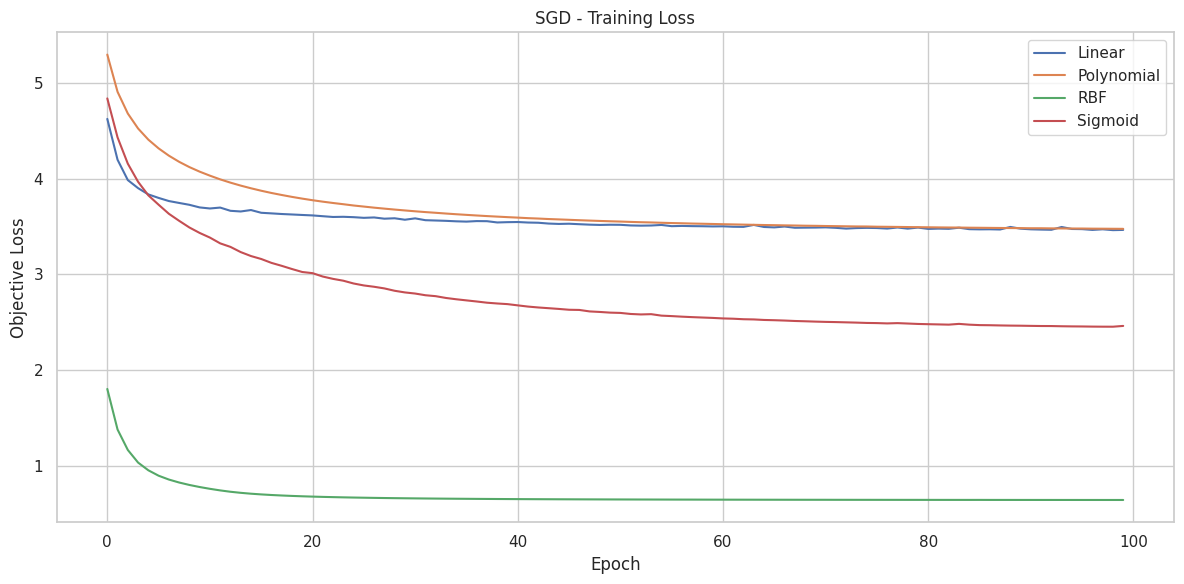

In [9]:

plt.figure(figsize=(12, 6))

for kernel_name, model_data in sgd_models.items():

    plt.plot(
        model_data["loss_history"],
        label=kernel_name
    )

plt.title("SGD - Training Loss")
plt.xlabel("Epoch")
plt.ylabel("Objective Loss")
plt.legend()

plt.tight_layout()
plt.show()


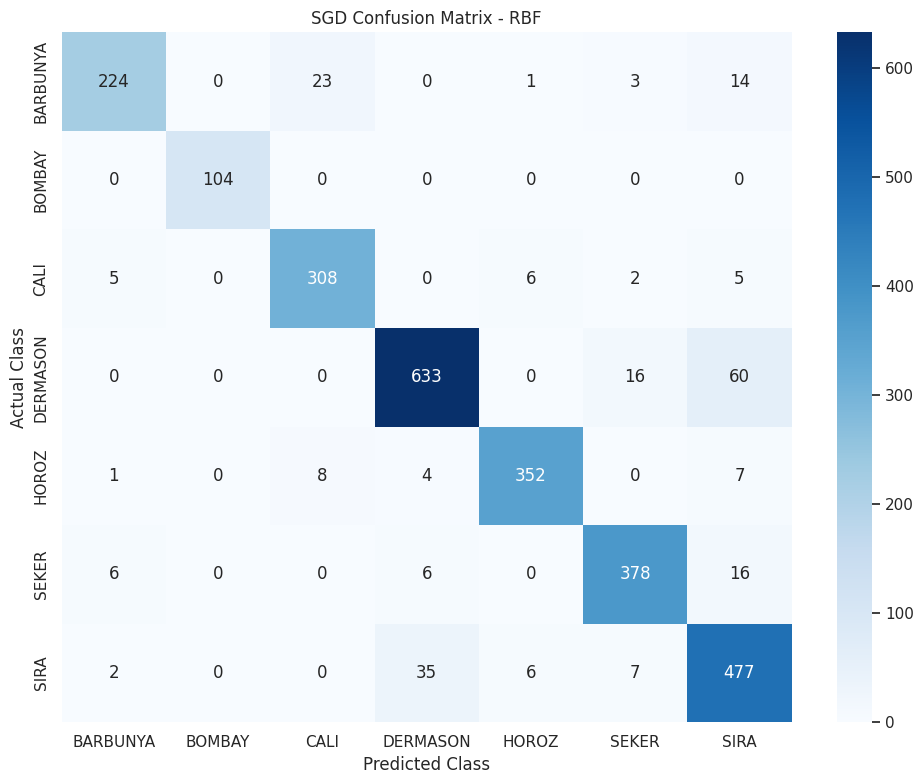

Best Kernel: RBF


In [10]:

best_kernel = sgd_results_df.iloc[0]["Kernel"]

best_model = sgd_models[best_kernel]

Z_test_best = best_model["feature_map"].transform(X_test)

y_pred = best_model["classes"][
    np.argmax(
        Z_test_best @ best_model["weights"],
        axis=1
    )
]

cm = confusion_matrix(
    y_test,
    y_pred,
    labels=classes
)

plt.figure(figsize=(10, 8))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=class_names,
    yticklabels=class_names
)

plt.title(f"SGD Confusion Matrix - {best_kernel}")
plt.xlabel("Predicted Class")
plt.ylabel("Actual Class")

plt.tight_layout()
plt.show()

print("Best Kernel:", best_kernel)


In [11]:

print(
    f"Classification Report - SGD with {best_kernel} Kernel"
)

print("=" * 60)

print(
    classification_report(
        y_test,
        y_pred,
        labels=classes,
        target_names=class_names,
        zero_division=0
    )
)


Classification Report - SGD with RBF Kernel
              precision    recall  f1-score   support

    BARBUNYA       0.94      0.85      0.89       265
      BOMBAY       1.00      1.00      1.00       104
        CALI       0.91      0.94      0.93       326
    DERMASON       0.93      0.89      0.91       709
       HOROZ       0.96      0.95      0.96       372
       SEKER       0.93      0.93      0.93       406
        SIRA       0.82      0.91      0.86       527

    accuracy                           0.91      2709
   macro avg       0.93      0.92      0.93      2709
weighted avg       0.92      0.91      0.91      2709



In [12]:

OUTPUT_DIR = Path("/kaggle/working/sgd_results")

OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

# Save comparison table
sgd_results_df.to_csv(
    OUTPUT_DIR / "sgd_comparison.csv",
    index=False
)

# Save models
joblib.dump(
    sgd_models,
    OUTPUT_DIR / "sgd_models.pkl"
)

# Save predictions for all kernels
predictions = {}

for kernel_name, model_data in sgd_models.items():

    Z_test = model_data["feature_map"].transform(X_test)

    scores = Z_test @ model_data["weights"]

    predictions[kernel_name] = model_data["classes"][
        np.argmax(scores, axis=1)
    ]

predictions_df = pd.DataFrame({
    "Actual": y_test
})

for kernel_name, pred in predictions.items():
    predictions_df[kernel_name] = pred

predictions_df.to_csv(
    OUTPUT_DIR / "sgd_predictions.csv",
    index=False
)

# Save configuration
config = {
    "optimizer": "Stochastic Gradient Descent",
    "learning_rate": SGD_CONFIG["learning_rate"],
    "epochs": SGD_CONFIG["epochs"],
    "regularization": SGD_CONFIG["regularization"],
    "n_components": SGD_CONFIG["n_components"],
    "kernels": list(KERNELS.keys()),
    "random_state": RANDOM_STATE,
    "classes": class_names
}

with open(OUTPUT_DIR / "sgd_config.json", "w") as f:
    json.dump(config, f, indent=4)

print("SGD results saved successfully!")

print("\nSaved files:")

for file in OUTPUT_DIR.iterdir():
    print(file.name)


SGD results saved successfully!

Saved files:
sgd_comparison.csv
sgd_config.json
sgd_predictions.csv
sgd_models.pkl
